In [2]:
import pandas as pd
import sqlite3

# Use a separate database for this exercise
db_path = "supply_chain.db"

print("Database location:", db_path)


Database location: supply_chain.db


## 1. Data Creation

In [3]:
# Products: three categories, with two products in each
products = pd.DataFrame({
    "ProductID": [1, 2, 3, 4, 5, 6],
    "ProductName": [
        "Laptop", "Monitor",
        "Desk", "Office Chair",
        "Notebook", "Pen Pack"
    ],
    "Category": [
        "Electronics", "Electronics",
        "Furniture", "Furniture",
        "Stationery", "Stationery"]})

# Suppliers: companies supplying the shipped products
suppliers = pd.DataFrame({
    "SupplierID": [1, 2, 3],
    "SupplierName": [
        "Tech Supply", "Office Furniture", "Paper and Pens"]})

# Warehouses: locations from which orders are handled
warehouses = pd.DataFrame({
    "WarehouseID": [1, 2, 3],
    "WarehouseName": [
        "Beirut Warehouse", "Abu Dhabi Warehouse", "Dubai Warehouse"
    ],
    "Location": ["Beirut", "Abu Dhabi", "Dubai"]})

# Confirm the data and record counts.
print("Products:", len(products))
display(products)

print("Suppliers:", len(suppliers))
display(suppliers)

print("Warehouses:", len(warehouses))
display(warehouses)

Products: 6


,ProductID,ProductName,Category
0,1,Laptop,Electronics
1,2,Monitor,Electronics
2,3,Desk,Furniture
3,4,Office Chair,Furniture
4,5,Notebook,Stationery
5,6,Pen Pack,Stationery


Suppliers: 3


,SupplierID,SupplierName
0,1,Tech Supply
1,2,Office Furniture
2,3,Paper and Pens


Warehouses: 3


,WarehouseID,WarehouseName,Location
0,1,Beirut Warehouse,Beirut
1,2,Abu Dhabi Warehouse,Abu Dhabi
2,3,Dubai Warehouse,Dubai


In [ ]:
# Orders: the date each order was placed

orders = pd.DataFrame({
    "OrderID": [101, 102, 103, 104],
    "OrderDate": [
        "2026-01-02", "2026-01-03",
        "2026-01-04", "2026-01-05"]})

orders["OrderDate"] = pd.to_datetime(orders["OrderDate"])

# Each row represents 1 product shipped for 1 order. Prices are in USD
shipments = pd.DataFrame({
    "ShipmentID":  [1,   2,   3,   4,   5,   6],
    "OrderID":     [101, 101, 102, 102, 103, 104],
    "ProductID":   [1,   2,   3,   4,   5,   6],
    "SupplierID":  [1,   1,   2,   2,   3,   3],
    "WarehouseID": [1,   1,   2,   2,   3,   3],
    "Quantity":    [10,  20,  15,  25,  100, 200],
    "UnitPrice":   [800, 200, 150, 100, 3,   2],
    "ShipmentDate": [
        "2026-01-03", "2026-01-03",
        "2026-01-05", "2026-01-05",
        "2026-01-07", "2026-01-08"]
    })

shipments["ShipmentDate"] = pd.to_datetime(shipments["ShipmentDate"])

print("Orders:", len(orders))
display(orders)

print("Shipment lines:", len(shipments)) 
display(shipments)

Orders: 4


,OrderID,OrderDate
0,101,2026-01-02
1,102,2026-01-03
2,103,2026-01-04
3,104,2026-01-05


Shipment lines: 6


,ShipmentID,OrderID,ProductID,SupplierID,WarehouseID,Quantity,UnitPrice,ShipmentDate
0,1,101,1,1,1,10,800,2026-01-03
1,2,101,2,1,1,20,200,2026-01-03
2,3,102,3,2,2,15,150,2026-01-05
3,4,102,4,2,2,25,100,2026-01-05
4,5,103,5,3,3,100,3,2026-01-07
5,6,104,6,3,3,200,2,2026-01-08


In [5]:
# Create the time / date table from the shipment dates.
dates = shipments[["ShipmentDate"]].drop_duplicates().copy()
dates = dates.rename(columns={"ShipmentDate": "Date"})

dates["Year"] = dates["Date"].dt.year
dates["Month"] =dates["Date"].dt.month
dates["Day"] = dates["Date"].dt.day

print("Dates:", len(dates))
display(dates)

Dates: 4


,Date,Year,Month,Day
0,2026-01-03,2026,1,3
2,2026-01-05,2026,1,5
4,2026-01-07,2026,1,7
5,2026-01-08,2026,1,8


## 2. Create database tables

In [6]:
with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    conn.executescript("""
        CREATE TABLE IF NOT EXISTS Products (
            ProductID INTEGER PRIMARY KEY,
            ProductName TEXT,
            Category TEXT);

        CREATE TABLE IF NOT EXISTS Suppliers (
            SupplierID INTEGER PRIMARY KEY,
            SupplierName TEXT);

        CREATE TABLE IF NOT EXISTS Warehouses (
            WarehouseID INTEGER PRIMARY KEY,
            WarehouseName TEXT,
            Location TEXT);

        CREATE TABLE IF NOT EXISTS Orders (
            OrderID INTEGER PRIMARY KEY,
            OrderDate TEXT);

        CREATE TABLE IF NOT EXISTS DimDate (
            Date TEXT PRIMARY KEY,
            Year INTEGER,
            Month INTEGER,
            Day INTEGER);

        CREATE TABLE IF NOT EXISTS Shipments (
            ShipmentID INTEGER PRIMARY KEY,
            OrderID INTEGER,
            ProductID INTEGER,
            SupplierID INTEGER,
            WarehouseID INTEGER,
            Quantity INTEGER,
            UnitPrice REAL,
            ShipmentDate TEXT,
            FOREIGN KEY (OrderID) REFERENCES Orders(OrderID),
            FOREIGN KEY (ProductID) REFERENCES Products(ProductID),
            FOREIGN KEY (SupplierID) REFERENCES Suppliers(SupplierID),
            FOREIGN KEY (WarehouseID) REFERENCES Warehouses(WarehouseID),
            FOREIGN KEY (ShipmentDate) REFERENCES DimDate(Date));
    """)


    tables = pd.read_sql_query("""
        SELECT name AS TableName
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name
    """, conn)

print("Tables created:", len(tables))
display(tables)

Tables created: 6


,TableName
0,DimDate
1,Orders
2,Products
3,Shipments
4,Suppliers
5,Warehouses


## 3. Load the sample data

In [7]:
# Match each database table to its DataFrame.
tables = {
    "Products": products,
    "Suppliers": suppliers,
    "Warehouses": warehouses,
    "Orders": orders,
    "DimDate": dates,
    "Shipments": shipments
}

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    # Clear previous data to avoid duplicates, starting with shipments to not break the deletions in SQLite 
    conn.execute("DELETE FROM Shipments")

    for name in ["Products", "Suppliers", "Warehouses", "Orders", "DimDate"]:
        conn.execute(f"DELETE FROM {name}")

    # Load the supporting tables first and shipments last
    for name, data in tables.items():
        data.to_sql(name, conn, if_exists="append", index=False)

        count = conn.execute(
            f"SELECT COUNT(*) FROM {name}"
        ).fetchone()[0]

        print(f"{name}: {count} rows")

display(pd.read_sql_query("SELECT * FROM Shipments", conn))

Products: 6 rows
Suppliers: 3 rows
Warehouses: 3 rows
Orders: 4 rows
DimDate: 4 rows
Shipments: 6 rows


,ShipmentID,OrderID,ProductID,SupplierID,WarehouseID,Quantity,UnitPrice,ShipmentDate
0,1,101,1,1,1,10,800.0,2026-01-03 00:00:00
1,2,101,2,1,1,20,200.0,2026-01-03 00:00:00
2,3,102,3,2,2,15,150.0,2026-01-05 00:00:00
3,4,102,4,2,2,25,100.0,2026-01-05 00:00:00
4,5,103,5,3,3,100,3.0,2026-01-07 00:00:00
5,6,104,6,3,3,200,2.0,2026-01-08 00:00:00


## Question 1 - Write a query to find the total quantity shipped for each product category.

In [8]:
with sqlite3.connect(db_path) as conn:
    quantity_by_category = pd.read_sql_query("""
        
        SELECT
            Products.Category,
            SUM(Shipments.Quantity) AS TotalQuantity

        FROM Shipments
        
        JOIN Products
            
            ON Shipments.ProductID = Products.ProductID
        
        GROUP BY Products.Category
        
        ORDER BY TotalQuantity DESC

    """, conn)

print("Total shipped:", quantity_by_category["TotalQuantity"].sum())
display(quantity_by_category)

Total shipped: 370


,Category,TotalQuantity
0,Stationery,300
1,Furniture,40
2,Electronics,30


## Question 2 - Identify warehouses with the most efficient shipping processes based on average shipping times.

In [ ]:
# Decided to do this Question in Python because it was easier for me to think it in Python and not in SQL
# Add the order date and warehouse name to each shipment
shipping_times = shipments.merge(orders, on="OrderID")
shipping_times = shipping_times.merge(warehouses, on="WarehouseID")


# Calculate the days between ordering and dispatching
shipping_times["ProcessingDays"] = (
    shipping_times["ShipmentDate"] - shipping_times["OrderDate"]
    ).dt.days

# Show the average for each warehouse, ordered by fastest 
average_days = shipping_times.groupby("WarehouseName")["ProcessingDays"].mean()


display(average_days.sort_values().rename("Average days").to_frame())

,Average days
WarehouseName,
Beirut Warehouse,1.0
Abu Dhabi Warehouse,2.0
Dubai Warehouse,3.0


## Question 3. Calculate the total value of shipments for each supplier

In [10]:
with sqlite3.connect(db_path) as conn:
    supplier_totals = pd.read_sql_query("""
        SELECT
            Suppliers.SupplierName,
            SUM(Shipments.Quantity * Shipments.UnitPrice) AS TotalValueUSD
        
        FROM Shipments
        
        JOIN Suppliers ON Shipments.SupplierID = Suppliers.SupplierID
        
        GROUP BY Suppliers.SupplierID, Suppliers.SupplierName
        
        ORDER BY TotalValueUSD DESC
        
    """, conn)

print("Total shipment value in USD:", supplier_totals["TotalValueUSD"].sum())
display(supplier_totals)

Total shipment value in USD: 17450.0


,SupplierName,TotalValueUSD
0,Tech Supply,12000.0
1,Office Furniture,4750.0
2,Paper and Pens,700.0


## Question 4. Retrieve the top 5 products with the highest total shipment quantities

In [11]:
with sqlite3.connect(db_path) as conn:
    top_products = pd.read_sql_query("""
        SELECT
            Products.ProductName,
            SUM(Shipments.Quantity) AS TotalQuantity
        
        FROM Shipments
        
        JOIN Products ON Shipments.ProductID = Products.ProductID
        
        GROUP BY Products.ProductID, Products.ProductName
        
        ORDER BY TotalQuantity DESC, Products.ProductID
        
        LIMIT 5
    
    """, conn)

print("Products displayed:", len(top_products))
display(top_products)

Products displayed: 5


,ProductName,TotalQuantity
0,Pen Pack,200
1,Notebook,100
2,Office Chair,25
3,Monitor,20
4,Desk,15


## Question 5. Create a report that shows the distribution of shipment values for each product category.

In [12]:
# How I understood it: Calculate the total shipment value for each category and its percentage of the overall value

with sqlite3.connect(db_path) as conn:
    category_values = pd.read_sql_query("""
        SELECT
            Products.Category,
            SUM(Shipments.Quantity * Shipments.UnitPrice) AS TotalValueUSD
        
        FROM Shipments
        
        JOIN Products ON Shipments.ProductID = Products.ProductID
        
        GROUP BY Products.Category
        
        ORDER BY TotalValueUSD DESC
    
    """, conn)

# Calculate each category's share of the total value.
total_value = category_values["TotalValueUSD"].sum()

category_values["Percentage"] = (
    category_values["TotalValueUSD"] / total_value * 100 ).round(2)

print("Categories:", len(category_values))
print("Total shipment value in USD:", total_value)
display(category_values)

Categories: 3
Total shipment value in USD: 17450.0


,Category,TotalValueUSD,Percentage
0,Electronics,12000.0,68.77
1,Furniture,4750.0,27.22
2,Stationery,700.0,4.01


### Main findings

- Electronics accounts for 68.77% of total shipment value, followed by Furniture at 27.22% and Stationery at 4.01%

- Although Stationery has the highest shipped quantity (300 units), it contributes the lowest shipment value because its products have lower unit prices

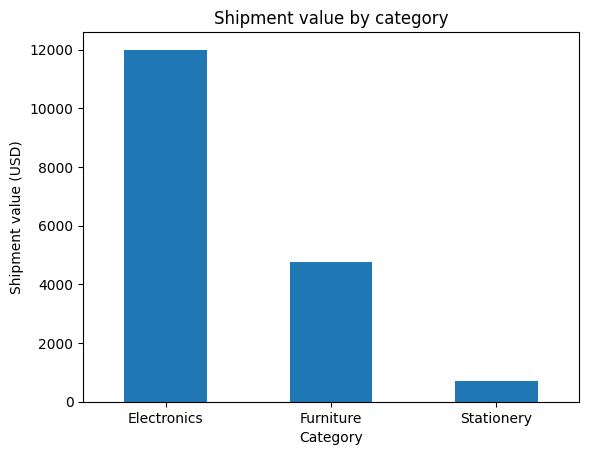

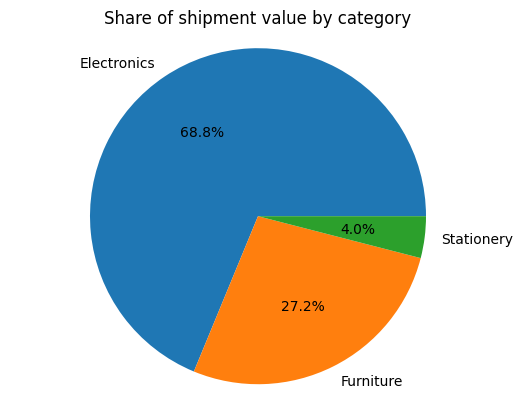

In [ ]:
import matplotlib.pyplot as plt

#Create a Bar CHart to show results
category_values.plot.bar(x="Category",
                        y="TotalValueUSD",
                        title="Shipment value by category",
                        legend=False,
                        rot=0)

plt.ylabel("Shipment value (USD)")
plt.xlabel("Category")

plt.show()

#Create a Pie Chart to show results
plt.pie(category_values["TotalValueUSD"],
    labels=category_values["Category"],
    autopct="%1.1f%%")

plt.title("Share of shipment value by category")
plt.axis("equal")
plt.show()

## AT - Question 6. Design a view that provides a consolidated summary of shipment and product performance, including total quantities, average shipping times, and shipment patterns.

In [14]:
with sqlite3.connect(db_path) as conn:
    conn.execute("DROP VIEW IF EXISTS ProductShipmentSummary")

    conn.execute("""
        CREATE VIEW ProductShipmentSummary AS

        SELECT
            p.ProductName,
            p.Category,
            strftime('%Y-%m', s.ShipmentDate) AS ShipmentMonth,
            COUNT(*) AS ShipmentLines,
            SUM(s.Quantity) AS TotalQuantity,
            ROUND(AVG(
                (strftime('%s', s.ShipmentDate)
                 - strftime('%s', o.OrderDate)) / 86400.0
            ), 2) AS AverageProcessingDays
        
        FROM Shipments s
        
        JOIN Products p ON s.ProductID = p.ProductID
        
        JOIN Orders o ON s.OrderID = o.OrderID
        
        GROUP BY
            p.ProductID, p.ProductName, p.Category,
            strftime('%Y-%m', s.ShipmentDate)
    """)

    summary = pd.read_sql_query("""
        SELECT *
        
        FROM ProductShipmentSummary
        
        ORDER BY TotalQuantity DESC
    
    """, conn)

print("Summary rows:", len(summary))
display(summary)

Summary rows: 6


,ProductName,Category,ShipmentMonth,ShipmentLines,TotalQuantity,AverageProcessingDays
0,Pen Pack,Stationery,2026-01,1,200,3.0
1,Notebook,Stationery,2026-01,1,100,3.0
2,Office Chair,Furniture,2026-01,1,25,2.0
3,Monitor,Electronics,2026-01,1,20,1.0
4,Desk,Furniture,2026-01,1,15,2.0
5,Laptop,Electronics,2026-01,1,10,1.0
